In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
df = pd.read_csv("data/ECG_10s_2500.csv")


In [15]:
df.head()

,0,1,2,3,4,5,6,7,8,9,...,2495,2496,2497,2498,2499,label,patient_id,day,count,glucose_values
0,0.000253,0.000137,0.000029,-0.000049,0.000003,0.000104,0.000218,0.000259,0.000381,0.000554,...,-0.001424,-0.001693,-0.001745,-0.001858,-0.001925,0,1,0,1,9.9
1,-0.002120,-0.002321,-0.002494,-0.002581,-0.002604,-0.002579,-0.002478,-0.002557,-0.002519,-0.002492,...,-0.000332,-0.000331,-0.000265,-0.000135,-0.000158,0,1,0,2,9.9
2,-0.000140,-0.000134,-0.000083,0.000044,0.000428,0.000807,0.001260,0.001525,0.001485,0.001241,...,-0.001994,-0.001875,-0.001705,-0.001598,-0.001508,0,1,0,3,9.9
3,-0.001413,-0.001567,-0.001539,-0.001662,-0.001679,-0.001672,-0.001582,-0.001538,-0.001463,-0.001292,...,-0.000607,-0.000543,-0.000557,-0.000511,-0.000490,0,1,0,4,9.9
4,-0.000645,-0.000753,-0.000781,-0.000851,-0.000889,-0.000837,-0.000850,-0.000712,-0.000671,-0.000657,...,-0.004922,-0.003484,-0.002461,-0.001812,-0.001340,0,1,0,5,9.9


In [4]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45630 entries, 0 to 45629
Columns: 2505 entries, 0 to glucose_values
dtypes: float64(2501), int64(4)
memory usage: 872.1 MB


,0,1,2,3,4,5,6,7,8,9,...,2495,2496,2497,2498,2499,label,patient_id,day,count,glucose_values
count,45630.000000,4.563000e+04,45630.000000,45630.000000,45630.000000,45630.000000,45630.000000,45630.000000,45630.000000,45630.000000,...,45630.000000,45630.000000,45630.000000,45630.000000,45630.000000,45630.000000,45630.000000,45630.000000,45630.000000,45630.000000
mean,-0.000018,-1.331885e-07,0.000024,0.000047,0.000061,0.000059,0.000044,0.000019,-0.000007,-0.000028,...,0.000046,0.000029,0.000005,-0.000019,-0.000033,0.053934,6.378238,1.825400,6192.608240,8.006156
std,0.006011,6.042477e-03,0.006084,0.006121,0.006144,0.006150,0.006141,0.006125,0.006112,0.006107,...,0.006498,0.006463,0.006420,0.006378,0.006355,0.225890,2.006788,1.419426,4821.450974,3.193503
min,-0.107135,-1.078101e-01,-0.108327,-0.108722,-0.109124,-0.109545,-0.109892,-0.109983,-0.110103,-0.110041,...,-0.114416,-0.105848,-0.105085,-0.105817,-0.106527,0.000000,1.000000,0.000000,1.000000,2.200000
25%,-0.002391,-2.381337e-03,-0.002382,-0.002371,-0.002371,-0.002381,-0.002403,-0.002413,-0.002413,-0.002421,...,-0.002382,-0.002380,-0.002390,-0.002412,-0.002421,0.000000,6.000000,1.000000,1993.000000,5.500000
50%,-0.000081,-6.546809e-05,-0.000045,-0.000031,-0.000036,-0.000032,-0.000045,-0.000056,-0.000071,-0.000086,...,-0.000045,-0.000048,-0.000066,-0.000084,-0.000091,0.000000,7.000000,2.000000,4823.000000,7.700000
75%,0.002017,2.026027e-03,0.002049,0.002060,0.002073,0.002069,0.002050,0.002027,0.002006,0.001983,...,0.002071,0.002052,0.002030,0.002020,0.002015,0.000000,8.000000,3.000000,10136.750000,9.800000
max,0.114852,1.143716e-01,0.113860,0.113332,0.112790,0.115302,0.121373,0.126935,0.131868,0.136318,...,0.143160,0.139594,0.136269,0.133315,0.130533,1.000000,9.000000,5.000000,17163.000000,22.200000


In [5]:
print("missing: \n",df.isna().sum(),"\n")      # Missing values per column
print("duplicates: \n",df.duplicated().sum()) # Duplicates


missing: 
 0                 0
1                 0
2                 0
3                 0
4                 0
                 ..
label             0
patient_id        0
day               0
count             0
glucose_values    0
Length: 2505, dtype: int64 

duplicates: 
 0


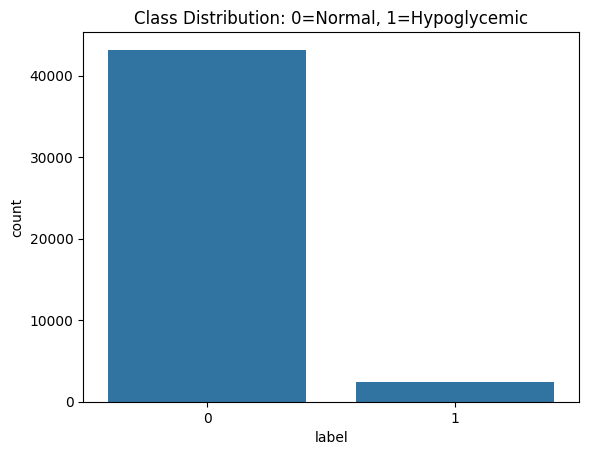

label
0    94.606618
1     5.393382
Name: proportion, dtype: float64

In [6]:
sns.countplot(x='label', data=df)
plt.title("Class Distribution: 0=Normal, 1=Hypoglycemic")
plt.show()

df['label'].value_counts(normalize=True) * 100


In [7]:
df['patient_id'].nunique()
df['patient_id'].value_counts()


patient_id
8    16560
7    14363
6     5621
2     4398
4     2326
3     1723
1      569
5       44
9       26
Name: count, dtype: int64

In [8]:
meta_cols = ['subset', 'patient_id', 'day', 'label', 'glucose_values']

# Identify numeric ECG columns automatically
ecg_cols = [c for c in df.columns if c not in meta_cols]

# Convert ECG part to numpy array
X = df[ecg_cols].to_numpy(dtype=float)
y = df['label'].to_numpy()

print(f"ECG shape: {X.shape}")   # Expect (n_samples, n_points)
print(f"Labels shape: {y.shape}")

ECG shape: (45630, 2501)
Labels shape: (45630,)


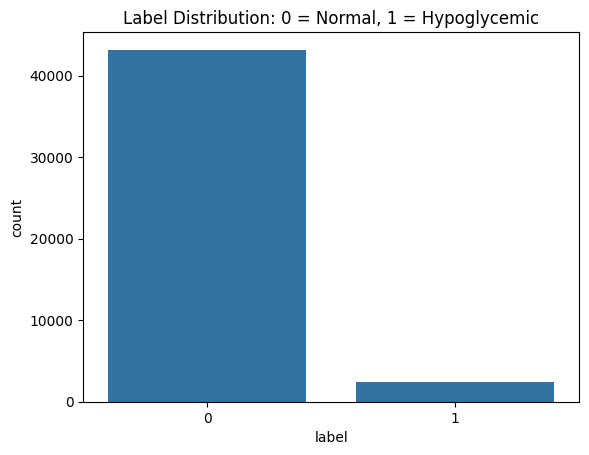

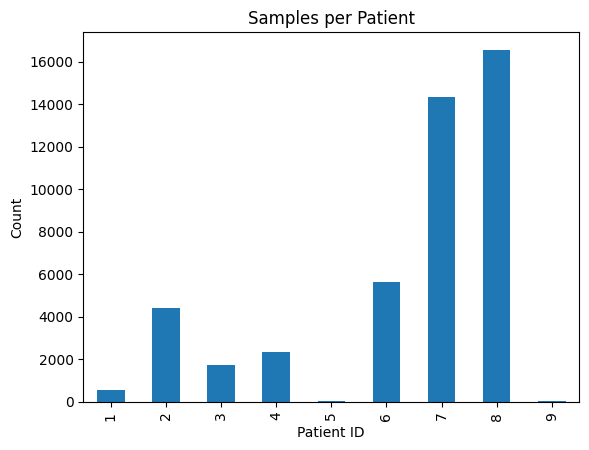

In [9]:
sns.countplot(x='label', data=df)
plt.title("Label Distribution: 0 = Normal, 1 = Hypoglycemic")
plt.show()

# Check samples per patient
df['patient_id'].value_counts().sort_index().plot(kind='bar')
plt.title("Samples per Patient")
plt.xlabel("Patient ID")
plt.ylabel("Count")
plt.show()


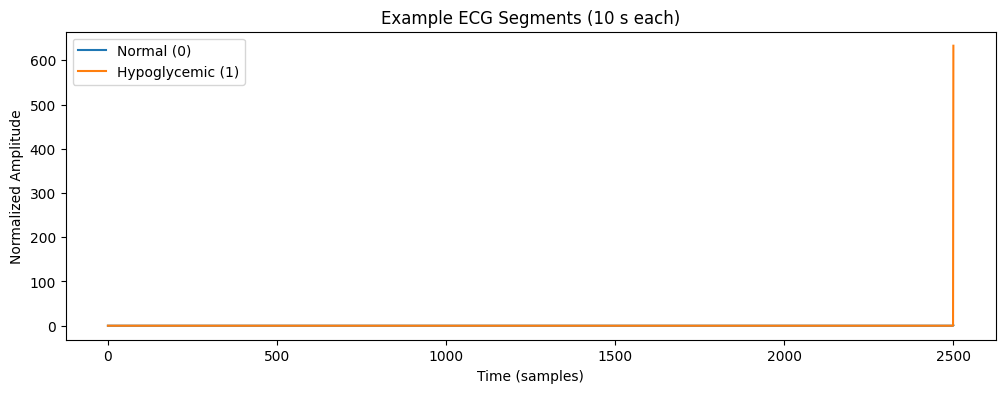

In [10]:
# Pick one normal and one hypoglycemic example
normal_idx = df[df['label'] == 0].index[0]
hypo_idx = df[df['label'] == 1].index[0]

plt.figure(figsize=(12,4))
plt.plot(X[normal_idx, :], label="Normal (0)")
plt.plot(X[hypo_idx, :], label="Hypoglycemic (1)")
plt.legend()
plt.title("Example ECG Segments (10 s each)")
plt.xlabel("Time (samples)")
plt.ylabel("Normalized Amplitude")
plt.show()


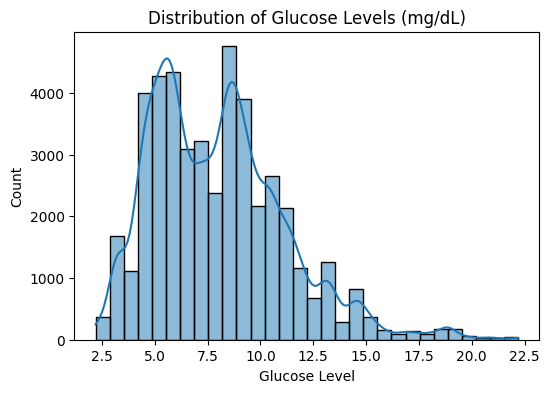

In [11]:
plt.figure(figsize=(6,4))
sns.histplot(df['glucose_values'], kde=True, bins=30)
plt.title("Distribution of Glucose Levels (mg/dL)")
plt.xlabel("Glucose Level")
plt.ylabel("Count")
plt.show()


In [26]:
df.tail()

,0,1,2,3,4,5,6,7,8,9,...,2495,2496,2497,2498,2499,label,patient_id,day,count,glucose_values
45625,-0.079235,-0.075126,-0.070535,-0.065619,-0.060455,-0.055014,-0.049507,-0.044106,-0.038774,-0.033461,...,-0.005577,-0.005308,-0.005095,-0.004862,-0.004668,0,9,2,116,5.0
45626,-0.004508,-0.004386,-0.004116,-0.003841,-0.003527,-0.003144,-0.002724,-0.002426,-0.002149,-0.001905,...,-0.012963,-0.013013,-0.012849,-0.012544,-0.011877,0,9,2,117,5.0
45627,-0.024339,-0.024702,-0.025131,-0.025622,-0.026324,-0.027089,-0.028078,-0.029077,-0.030213,-0.031331,...,-0.013777,-0.013643,-0.013532,-0.013401,-0.013270,0,9,2,122,5.3
45628,0.086670,0.091881,0.097098,0.102775,0.108880,0.115302,0.121373,0.126935,0.131868,0.136318,...,0.116554,0.116320,0.116033,0.115689,0.115296,0,9,2,135,4.2
45629,0.114852,0.114372,0.113860,0.113332,0.112790,0.112389,0.111804,0.111026,0.110015,0.108766,...,-0.003447,-0.003165,-0.002756,-0.002437,-0.002143,0,9,2,136,4.2


In [4]:
df.groupby('patient_id')['label'].sum()


patient_id
1      54
2     372
3       0
4     358
5       0
6       0
7       3
8    1674
9       0
Name: label, dtype: int64

In [4]:

hypo_patients = [1, 2, 4, 7, 8]  
normal_only_patients = [3, 5, 6, 9]  


def normalize_segments(X):

    mean = np.mean(X, axis=1, keepdims=True)
    std = np.std(X, axis=1, keepdims=True) + 1e-8
    return (X - mean) / std

results = []

for test_patient in hypo_patients:
    print(f"\n=== Test Patient: {test_patient} ===")

    train_patients = [p for p in hypo_patients + normal_only_patients if p != test_patient]
    
    
    train_df = df[df['patient_id'].isin(train_patients)]
    test_df = df[df['patient_id'] == test_patient]
    
    val_patient = np.random.choice([p for p in hypo_patients if p not in [test_patient]])
    val_df = train_df[train_df['patient_id'] == val_patient]
    train_df = train_df[train_df['patient_id'] != val_patient]

    print(f"Train patients: {sorted(train_df['patient_id'].unique())}")
    print(f"Validation patient: {val_patient}")
    print(f"Test patient: {test_patient}")

  
    X_train = train_df.iloc[:, 0:2500].values
    y_train = train_df['label'].values

    X_val = val_df.iloc[:, 0:2500].values
    y_val = val_df['label'].values

    X_test = test_df.iloc[:, 0:2500].values
    y_test = test_df['label'].values

  
    X_train = normalize_segments(X_train)
    X_val = normalize_segments(X_val)
    X_test = normalize_segments(X_test)

   
    X_train = X_train.reshape(-1, 2500, 1)
    X_val = X_val.reshape(-1, 2500, 1)
    X_test = X_test.reshape(-1, 2500, 1)

    print(f"Train shape: {X_train.shape}, Val shape: {X_val.shape}, Test shape: {X_test.shape}")

    
    from sklearn.utils.class_weight import compute_class_weight

    class_weights_values = compute_class_weight(
        class_weight='balanced',
        classes=np.unique(y_train),
        y=y_train
    )
    class_weights = {i: w for i, w in enumerate(class_weights_values)}

    print("Class weights:", class_weights)

    



=== Test Patient: 1 ===
Train patients: [np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(9)]
Validation patient: 8
Test patient: 1
Train shape: (28501, 2500, 1), Val shape: (16560, 2500, 1), Test shape: (569, 2500, 1)
Class weights: {0: np.float64(0.5131986459233651), 1: np.float64(19.441336971350616)}

=== Test Patient: 2 ===
Train patients: [np.int64(1), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(8), np.int64(9)]
Validation patient: 7
Test patient: 2
Train shape: (26869, 2500, 1), Val shape: (14363, 2500, 1), Test shape: (4398, 2500, 1)
Class weights: {0: np.float64(0.5420853004075374), 1: np.float64(6.440316395014381)}

=== Test Patient: 4 ===
Train patients: [np.int64(1), np.int64(3), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
Validation patient: 2
Test patient: 4
Train shape: (38906, 2500, 1), Val shape: (4398, 2500, 1), Test shape: (2326, 2500, 1)
Class weights: {0: np.float64(0.5232817753866846), 1: 